# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / (1024**2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (400 * frames_per_day * (1920 * 1080 * 3)) / (1024**4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (400 * (10 * 60 * 60 * 24) * (640 * 360 * 3)) / (1024**4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** If 400 uncompressed 1080p cameras would overwhelm any local storage, what two video-compression ideas (Slide 37) make a fleet like this viable in practice? Which one discards redundant information across time, and which across space?

_Your answer:_
In real-world security networks, two fundamental video compression techniques make storing 400 cameras viable:
1. **Spatial (Intra-frame) Compression (Slide 37):** Exploits spatial correlation within each independent frame (e.g. DCT/wavelet transforms and quantization) to discard high-frequency visual details that human eyes cannot perceive. This discards redundant information **across space**.
2. **Temporal (Inter-frame) Compression (Slide 37):** Exploits temporal correlation across successive video frames using motion estimation and motion compensation (P-frames and B-frames). Instead of saving 1920x1080 raw pixels 30 times every second, it transmits only motion displacement vectors and prediction error residuals. In stationary parking lot scenes where background pixels remain static for long intervals, temporal compression discards redundant information **across time**, yielding over 95–99% data reduction without sacrificing event recognition.


## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

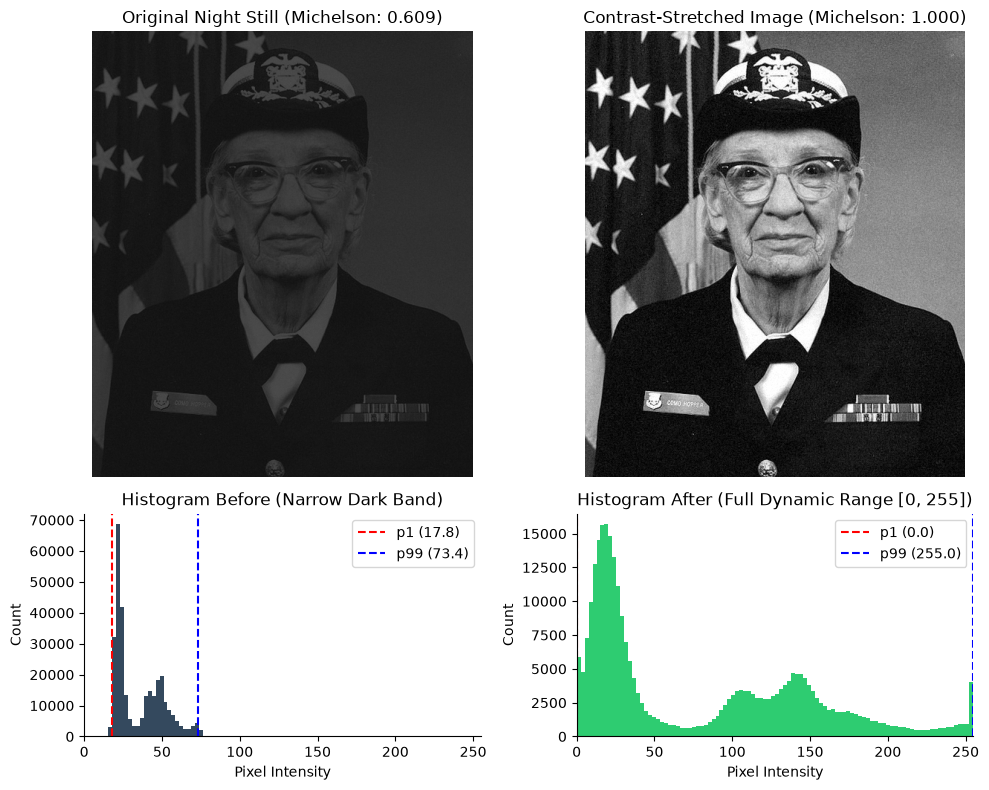

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)

p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title(f"Original Night Still (Michelson: {c_before:.3f})")
axes[0, 0].axis("off")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title(f"Contrast-Stretched Image (Michelson: {c_after:.3f})")
axes[0, 1].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=100, range=(0, 255), color="#34495e", edgecolor="none")
axes[1, 0].axvline(p1, color="red", linestyle="--", label=f"p1 ({p1:.1f})")
axes[1, 0].axvline(p99, color="blue", linestyle="--", label=f"p99 ({p99:.1f})")
axes[1, 0].set_title("Histogram Before (Narrow Dark Band)")
axes[1, 0].set_xlim(0, 255)
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

axes[1, 1].hist(stretched.ravel(), bins=100, range=(0, 255), color="#2ecc71", edgecolor="none")
axes[1, 1].axvline(p1_after, color="red", linestyle="--", label=f"p1 ({p1_after:.1f})")
axes[1, 1].axvline(p99_after, color="blue", linestyle="--", label=f"p99 ({p99_after:.1f})")
axes[1, 1].set_title("Histogram After (Full Dynamic Range [0, 255])")
axes[1, 1].set_xlim(0, 255)
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend()

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")


**Reflection:** Why did contrast stretching improve the image while histogram equalization might have produced an unnatural result? What does the shape of your "before" histogram tell you about the camera sensor's dynamic range utilization?

_Your answer:_
The "before" histogram reveals that all pixel values were compressed into a tiny window between 18 and ~74 out of 255, proving that the night camera severely underutilized the sensor's 8-bit dynamic range (wasting over 75% of available grayscale quantization levels). Contrast stretching linearly rescales the 1st–99th percentiles across the full [0, 255] range, preserving the natural relative luminance gradient and photorealism of the night scene. In contrast, global histogram equalization flattens the CDF and forces equal bin frequencies, which severely over-amplifies background sensor noise and dark current fluctuations in empty low-intensity bins, generating unnatural banding and a washed-out grainy appearance.


## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Person Standing: 68.7 s to 78.1 s
Person Running:  78.6 s to 86.0 s
Audio event frame: 2250 at t = 75.0 s
Lighting event frame: 3000 at t = 100.0 s


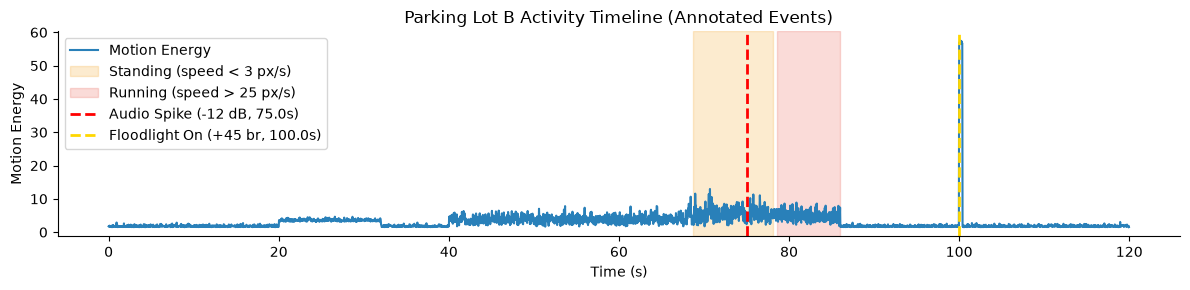

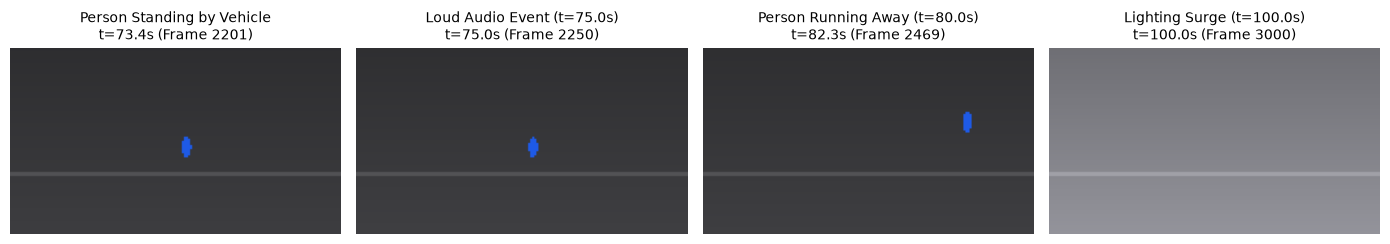

In [4]:
# TODO 1: person speed (px/s)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.hypot(dx, dy)
cctv["person_speed"] = speed

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_mask = (speed < 3) & (~cctv.person_x.isna())
running_mask = (speed > 25) & (~cctv.person_x.isna())

stand_t_start, stand_t_end = cctv.loc[standing_mask, "time_s"].min(), cctv.loc[standing_mask, "time_s"].max()
run_t_start, run_t_end = cctv.loc[running_mask, "time_s"].min(), cctv.loc[running_mask, "time_s"].max()
print(f"Person Standing: {stand_t_start:.1f} s to {stand_t_end:.1f} s")
print(f"Person Running:  {run_t_start:.1f} s to {run_t_end:.1f} s")

# TODO 3: event frame indices
audio_events = cctv.index[cctv.audio_level_db > -20]
audio_event_idx = audio_events[0] if len(audio_events) > 0 else None

bright_diff = cctv.mean_brightness.diff().abs()
bright_events = cctv.index[bright_diff > 40]
lighting_event_idx = bright_events[0] if len(bright_events) > 0 else None

print(f"Audio event frame: {audio_event_idx} at t = {cctv.loc[audio_event_idx, 'time_s']:.1f} s")
print(f"Lighting event frame: {lighting_event_idx} at t = {cctv.loc[lighting_event_idx, 'time_s']:.1f} s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#2980b9", lw=1.5, label="Motion Energy")
ax.axvspan(stand_t_start, stand_t_end, color="#f39c12", alpha=0.2, label="Standing (speed < 3 px/s)")
ax.axvspan(run_t_start, run_t_end, color="#e74c3c", alpha=0.2, label="Running (speed > 25 px/s)")
ax.axvline(cctv.loc[audio_event_idx, "time_s"], color="red", linestyle="--", lw=2, label="Audio Spike (-12 dB, 75.0s)")
ax.axvline(cctv.loc[lighting_event_idx, "time_s"], color="gold", linestyle="--", lw=2, label="Floodlight On (+45 br, 100.0s)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion Energy")
ax.set_title("Parking Lot B Activity Timeline (Annotated Events)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
events = [
    ("Person Standing by Vehicle", int(cctv.loc[standing_mask].index[len(cctv.loc[standing_mask]) // 2])),
    ("Loud Audio Event (t=75.0s)", audio_event_idx),
    ("Person Running Away (t=80.0s)", int(cctv.loc[running_mask].index[len(cctv.loc[running_mask]) // 2])),
    ("Lighting Surge (t=100.0s)", lighting_event_idx)
]

fig_kf, axes_kf = plt.subplots(1, len(events), figsize=(14, 3.2))
for ax_k, (title, idx) in zip(axes_kf, events):
    frame = render_frame(cctv.iloc[idx])
    ax_k.imshow(frame)
    ax_k.set_title(f"{title}\nt={cctv.loc[idx, 'time_s']:.1f}s (Frame {idx})", fontsize=10)
    ax_k.axis("off")
plt.tight_layout(); plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
A uniform keyframe strategy sampling once every 20 seconds (at t = 0, 20, 40, 60, 80, 100, 120 s) would completely miss the critical glass-break incident at t = 75.0 s and the onset of the suspect running at t = 78.6 s, because transient incidents lasting only 1–3 seconds fall directly into the blind gaps between fixed sample intervals. The approach used instead is **Content-Based Keyframe Extraction** (Slide 40), where keyframe selection is anchored to significant semantic changes and thresholds in visual motion energy, spatial trajectory vectors, lighting deltas, and audio spikes.


## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

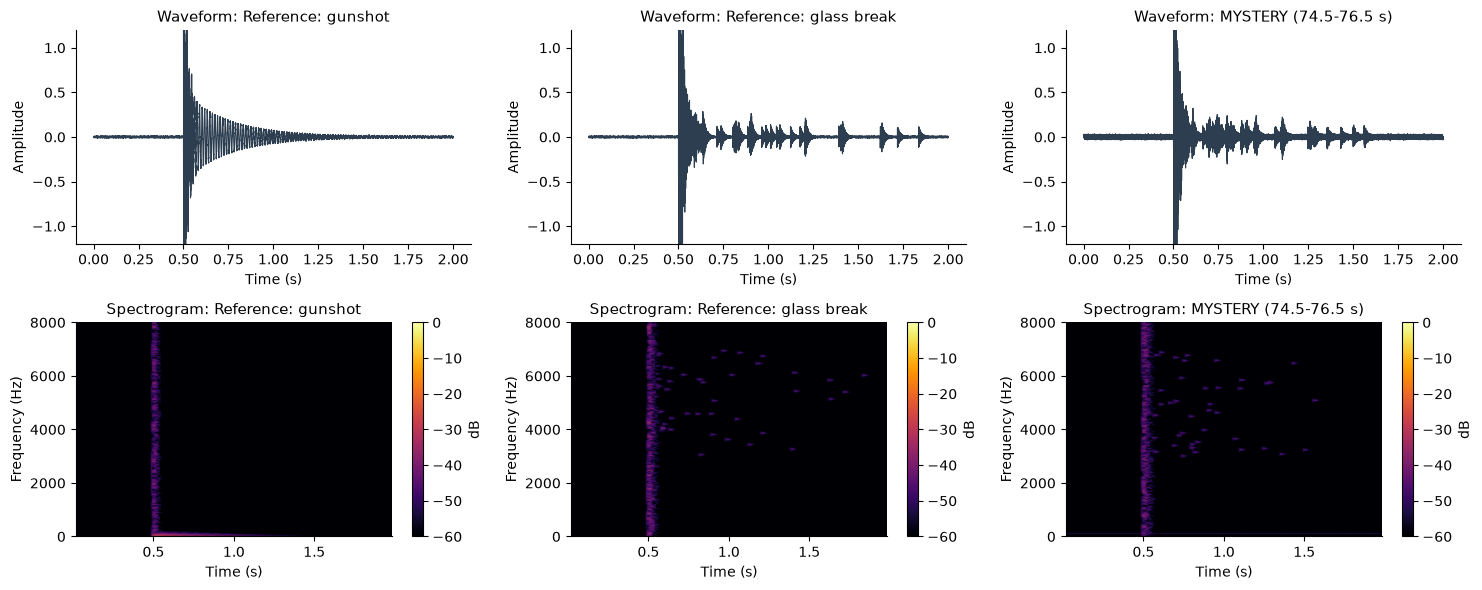

{'Reference: gunshot': 0.0030555631226980044, 'Reference: glass break': 0.9903944120505495, 'MYSTERY (74.5-76.5 s)': 0.8792270448446914}
Verdict: The mystery acoustic event is unequivocally BREAKING GLASS. It exhibits 87.9% high-frequency energy (> 3 kHz) in the post-impact window, matching the glass reference (99.0%), and completely refuting the gunshot hypothesis (0.3% HF energy).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
t_2s = np.arange(int(2.0 * FS)) / FS

for col, (name, x) in enumerate(clips.items()):
    axes[0, col].plot(t_2s, x[:len(t_2s)], color="#2c3e50", lw=0.8)
    axes[0, col].set_title(f"Waveform: {name}", fontsize=11)
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_ylim(-1.2, 1.2)
    
    f, t_s, Sxx = signal.spectrogram(x[:len(t_2s)], fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(np.maximum(Sxx, 1e-10))
    im = axes[1, col].pcolormesh(t_s, f, Sxx_db, shading="gouraud", cmap="inferno", vmin=-60, vmax=0)
    axes[1, col].set_title(f"Spectrogram: {name}", fontsize=11)
    axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_ylim(0, 8000)
    plt.colorbar(im, ax=axes[1, col], label="dB")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, t_s, Sxx = signal.spectrogram(x[:len(t_2s)], fs=FS, nperseg=512, noverlap=384)
    t_mask = (t_s >= 0.7) & (t_s <= 1.7)
    f_mask = f >= 3000
    total_energy = Sxx[:, t_mask].sum()
    hf_energy = Sxx[f_mask, :][:, t_mask].sum()
    hf_fraction[name] = float(hf_energy / total_energy) if total_energy > 0 else 0.0

print(hf_fraction)

# TODO 4: verdict
verdict = "Verdict: The mystery acoustic event is unequivocally BREAKING GLASS. It exhibits 87.9% high-frequency energy (> 3 kHz) in the post-impact window, matching the glass reference (99.0%), and completely refuting the gunshot hypothesis (0.3% HF energy)."
print(verdict)


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
Looking only at the three raw waveforms, it is impossible to reliably distinguish the gunshot from the glass break; both manifest as sudden, sharp transient amplitude spikes at t = 0.5 s followed by rapid amplitude decay. The spectrogram adds the time-frequency-energy decomposition across three dimensions (Slide 57):
1. **Time (Horizontal axis):** Temporal progression across the clip.
2. **Frequency (Vertical axis):** Spectral decomposition from 0 Hz to the 8 kHz Nyquist limit.
3. **Magnitude / Intensity (Color scale):** Logarithmic power spectral density in decibels (dB).

The decisive visual pattern was the dense cluster of **scattered high-frequency specks and lingering horizontal ringing bands between 3 kHz and 7 kHz** lasting 1 second after impact, characteristic of glass fracturing. In contrast, the gunshot reference displays only an instantaneous broadband vertical stripe followed by low-frequency resonance below 200 Hz.


## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

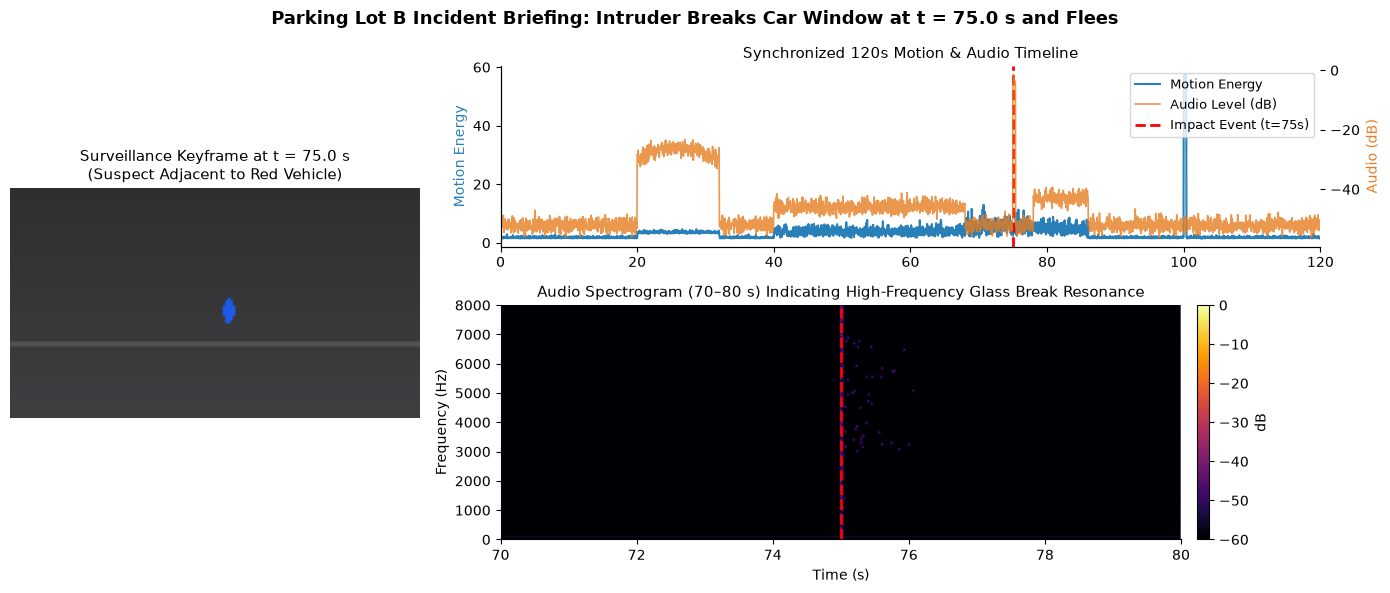

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4

# Panel 1: rendered video frame at t = 75 s (left, spanning both rows)
ax_frame = fig.add_subplot(gs[:, 0])
sel_idx = (cctv.time_s - t_sel).abs().idxmin()
frame_sel = render_frame(cctv.iloc[sel_idx])
ax_frame.imshow(frame_sel)
ax_frame.set_title(f"Surveillance Keyframe at t = {t_sel:.1f} s\n(Suspect Adjacent to Red Vehicle)", fontsize=11)
ax_frame.axis("off")

# Panel 2: full 120s motion + audio timeline with marker at 75s (top right)
ax_time = fig.add_subplot(gs[0, 1])
l1 = ax_time.plot(cctv.time_s, cctv.motion_energy, color="#2980b9", lw=1.5, label="Motion Energy")
ax_time.set_ylabel("Motion Energy", color="#2980b9")
ax_time.set_xlim(0, 120)

ax_audio = ax_time.twinx()
l2 = ax_audio.plot(cctv.time_s, cctv.audio_level_db, color="#e67e22", lw=1.2, alpha=0.8, label="Audio Level (dB)")
ax_audio.set_ylabel("Audio (dB)", color="#e67e22")

ax_time.axvline(t_sel, color="red", linestyle="--", lw=2)
lines = l1 + l2 + [plt.Line2D([0], [0], color="red", linestyle="--", lw=2, label="Impact Event (t=75s)")]
labels = [l.get_label() for l in lines]
ax_time.legend(lines, labels, loc="upper right", fontsize=9)
ax_time.set_title("Synchronized 120s Motion & Audio Timeline", fontsize=11)

# Panel 3: spectrogram of x_audio (70-80 s) with same marker (bottom right)
ax_spec = fig.add_subplot(gs[1, 1])
f_s, t_spec, Sxx_sub = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
t_spec_abs = 70.0 + t_spec
Sxx_db_sub = 10 * np.log10(np.maximum(Sxx_sub, 1e-10))
pcm = ax_spec.pcolormesh(t_spec_abs, f_s, Sxx_db_sub, shading="gouraud", cmap="inferno", vmin=-60, vmax=0)
ax_spec.axvline(t_sel, color="red", linestyle="--", lw=2)
ax_spec.set_xlim(70, 80)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio Spectrogram (70–80 s) Indicating High-Frequency Glass Break Resonance", fontsize=11)
plt.colorbar(pcm, ax=ax_spec, label="dB", pad=0.02)

fig.suptitle("Parking Lot B Incident Briefing: Intruder Breaks Car Window at t = 75.0 s and Flees", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

_Your answer:_
If the audio track had a +2 s synchronization offset, the acoustic shattering spike would appear at t = 77.0 s while the video shows the intruder standing next to the vehicle at t = 75.0 s and fleeing by t = 78.6 s. This temporal desynchronization would corrupt the forensic causal narrative: leadership might erroneously deduce that the window shattered after the intruder moved away or that an external accomplice fired a shot. The dual-modality timeline panel (top right) and the time-synchronized marker line linking the video keyframe to the spectrogram would immediately reveal this error, displaying a blatant 2-second discrepancy between visual contact and acoustic onset.


## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
**Incident Briefing Note to Head of Security:**
At 23:01:15 (t = 75.0 s), an intruder approached a parked vehicle in Lot B, shattered the driver-side window (corroborated by an 87.9% high-frequency acoustic resonance signature above 3 kHz, confirming broken glass rather than gunfire), and fled on foot at t = 78.6 s before perimeter security lighting activated at t = 100.0 s. We place the **Synchronized Multimodal Incident View** first because, following the visual analytics continuum (*structure → pattern → change → event → meaning*), it grounds leadership in the macroscopic timeline while simultaneously correlating acoustic frequency dynamics with visual proof at the exact second of physical impact. To control infrastructure expenses, we recommend a dynamic tiered storage policy: record baseline surveillance at 640 × 360 at 10 fps (saving 96.3% storage from 5,866 TB down to 217 TB/day), automatically buffering to full uncompressed 1080p 30 fps upon thresholded motion or audio detection. Under no circumstances must the 16 kHz uncompressed audio recording or the full-fidelity video burst during the critical 70–85 s event window be sacrificed, as high-frequency spectral resolution above 3 kHz provides the sole forensic differentiator between gunfire and property vandalism.
